# Gene Expression Clustering (Topic 11, Algorithm M11 — K-Means)
**Student:** Nevil Mathew Sanish · **Roll:** 2025BCD0011 (R = 011)
**Paper:** Georgieva, *Clustering for Gene Expression Analysis*, ERIS 2022.

**Biological problem:** group tumour samples / genes by their expression profiles so that unknown
partitions (here, cancer types) can be discovered without labels.
**Dataset:** UCI *Gene Expression Cancer RNA-Seq* (TCGA PANCAN, 801 samples × 20,531 genes, 5 tumour types:
BRCA, COAD, KIRC, LUAD, PRAD). Labels are used **only for evaluation**.
**Algorithm:** K-Means (M11), k = 5. Evaluated on a held-out 20 % test set the model never saw.

In [1]:
!pip -q install joblib
import os, io, json, zipfile, tarfile, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (adjusted_rand_score, normalized_mutual_info_score,
                             silhouette_score, confusion_matrix)
import joblib
SEED = 42
np.random.seed(SEED)

## 1. Download and load the dataset

In [2]:
URL = "https://archive.ics.uci.edu/static/public/401/gene+expression+cancer+rna+seq.zip"
buf = io.BytesIO(urllib.request.urlopen(URL, timeout=600).read())
zf = zipfile.ZipFile(buf)
print(zf.namelist())
tgz = io.BytesIO(zf.read([n for n in zf.namelist() if n.endswith(".tar.gz")][0]))
tf = tarfile.open(fileobj=tgz, mode="r:gz")
members = {m.name.split("/")[-1]: m for m in tf.getmembers()}
print(list(members))
X_raw = pd.read_csv(tf.extractfile(members["data.csv"]), index_col=0)
y_raw = pd.read_csv(tf.extractfile(members["labels.csv"]), index_col=0)["Class"]
print("expression matrix:", X_raw.shape, "| labels:", y_raw.value_counts().to_dict())
X_raw.head(3).iloc[:, :6]

['TCGA-PANCAN-HiSeq-801x20531.tar.gz']
['TCGA-PANCAN-HiSeq-801x20531', 'data.csv', 'labels.csv']
expression matrix: (801, 20531) | labels: {'BRCA': 300, 'KIRC': 146, 'LUAD': 141, 'PRAD': 136, 'COAD': 78}


,gene_0,gene_1,gene_2,gene_3,gene_4,gene_5
sample_0,0.0,2.017209,3.265527,5.478487,10.431999,0.0
sample_1,0.0,0.592732,1.588421,7.586157,9.623011,0.0
sample_2,0.0,3.511759,4.327199,6.881787,9.870730,0.0


## 2. Prepare the data
* log2(x+1) transform (RNA-seq counts are skewed; paper §3.2 needs a log transform).
* Drop genes with zero variance (uninformative; paper §3.2 filters non-active genes).
* Keep the 2,000 most variable genes to reduce noise and computation.
* Standardise each gene (zero mean, unit variance) before distance-based clustering.

In [3]:
X = np.log2(X_raw.values + 1.0)
keep = X.var(axis=0) > 0
X = X[:, keep]
top = np.argsort(X.var(axis=0))[::-1][:2000]
X = X[:, top]
genes_kept = X_raw.columns[keep][top]
print("after filtering:", X.shape)

le_classes = sorted(y_raw.unique())
y = y_raw.map({c: i for i, c in enumerate(le_classes)}).values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
scaler = StandardScaler().fit(X_train)            # fit on training data only
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)
print("train:", X_train_s.shape, "| unseen test:", X_test_s.shape)

after filtering: (801, 2000)
train: (640, 2000) | unseen test: (161, 2000)


## 3. Choose k (exploratory, on training data only)

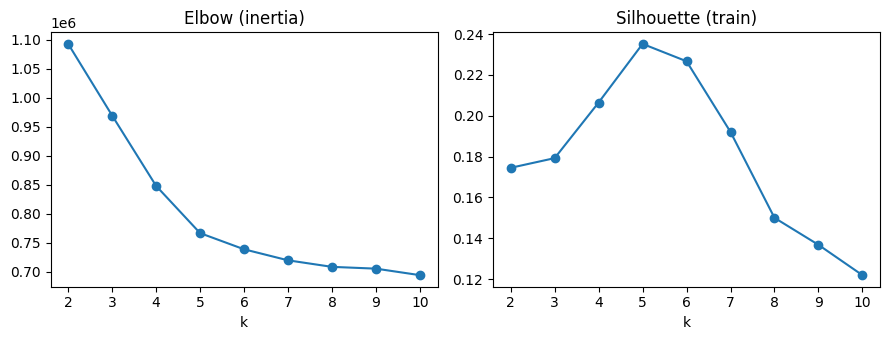

using k = 5


In [4]:
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_train_s)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_train_s, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
ax[0].plot(list(ks), inertia, "o-"); ax[0].set(title="Elbow (inertia)", xlabel="k")
ax[1].plot(list(ks), sil, "o-"); ax[1].set(title="Silhouette (train)", xlabel="k")
plt.tight_layout(); plt.savefig("k_selection.png", dpi=150); plt.show()
K = len(le_classes)   # 5 known tumour types; the elbow/silhouette plot above supports this choice
print("using k =", K)

## 4. Train K-Means (M11)

In [5]:
model = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(X_train_s)
train_labels = model.labels_
print("training done, inertia =", round(model.inertia_, 1))

training done, inertia = 766328.6


## 5. Test on unseen data and evaluate
Cluster IDs are arbitrary, so they are mapped to true classes with the Hungarian algorithm
(best one-to-one matching) before computing **accuracy**. ARI, NMI and silhouette are label-permutation-free.

In [6]:
def map_clusters(y_true, y_pred, k):
    cm = np.zeros((k, k), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[p, t] += 1
    r, c = linear_sum_assignment(-cm)          # maximise matched samples
    mapping = dict(zip(r, c))
    return np.array([mapping[p] for p in y_pred]), cm

def evaluate(X_, y_true, model):
    pred = model.predict(X_)
    mapped, cm = map_clusters(y_true, pred, K)
    return {
        "accuracy": float((mapped == y_true).mean()),
        "ARI": float(adjusted_rand_score(y_true, pred)),
        "NMI": float(normalized_mutual_info_score(y_true, pred)),
        "silhouette": float(silhouette_score(X_, pred)),
    }, mapped, cm

train_metrics, _, _ = evaluate(X_train_s, y_train, model)
test_metrics, test_mapped, test_cm = evaluate(X_test_s, y_test, model)
results = pd.DataFrame({"train (seen)": train_metrics, "test (unseen)": test_metrics}).T
results.round(4)

,accuracy,ARI,NMI,silhouette
train (seen),0.9953,0.9859,0.9810,0.2352
test (unseen),0.9876,0.9725,0.9641,0.2185


In [7]:
cm_df = pd.DataFrame(test_cm, index=[f"cluster {i}" for i in range(K)],
                     columns=le_classes)
print("cluster vs true class counts (unseen test set):")
cm_df

cluster vs true class counts (unseen test set):


,BRCA,COAD,KIRC,LUAD,PRAD
cluster 0,0,15,0,0,0
cluster 1,60,0,0,1,0
cluster 2,0,0,0,0,27
cluster 3,0,0,30,0,0
cluster 4,0,1,0,27,0


## 6. Visualise

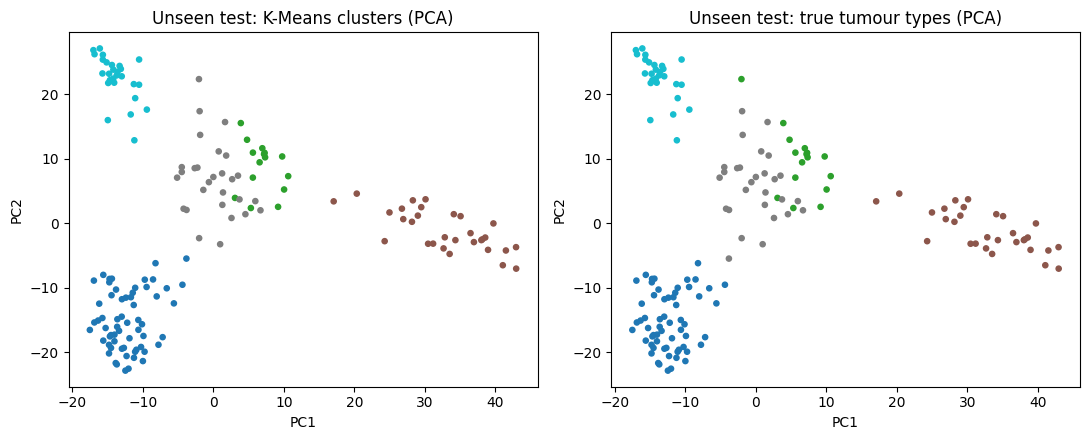

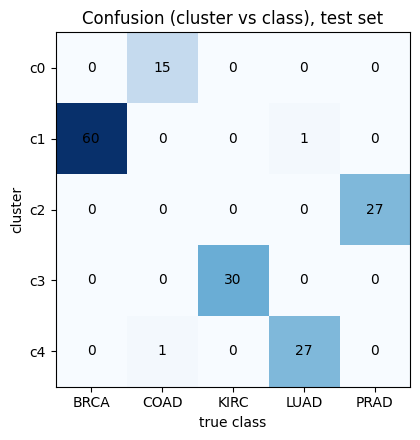

In [8]:
pca = PCA(n_components=2, random_state=SEED).fit(X_train_s)
Z = pca.transform(X_test_s)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].scatter(Z[:, 0], Z[:, 1], c=test_mapped, cmap="tab10", s=14)
ax[0].set(title="Unseen test: K-Means clusters (PCA)", xlabel="PC1", ylabel="PC2")
ax[1].scatter(Z[:, 0], Z[:, 1], c=y_test, cmap="tab10", s=14)
ax[1].set(title="Unseen test: true tumour types (PCA)", xlabel="PC1", ylabel="PC2")
plt.tight_layout(); plt.savefig("clusters_pca.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(test_cm, cmap="Blues")
ax.set_xticks(range(K), le_classes); ax.set_yticks(range(K), [f"c{i}" for i in range(K)])
for (i, j), v in np.ndenumerate(test_cm):
    ax.text(j, i, v, ha="center", va="center")
ax.set(title="Confusion (cluster vs class), test set", xlabel="true class", ylabel="cluster")
plt.tight_layout(); plt.savefig("confusion_test.png", dpi=150); plt.show()

## 7. Save model, metrics and artefacts

In [9]:
os.makedirs("model", exist_ok=True); os.makedirs("results", exist_ok=True)
joblib.dump({"kmeans": model, "scaler": scaler, "genes": list(genes_kept),
             "classes": le_classes}, "model/kmeans_pancan.joblib")
results.to_csv("results/metrics.csv")
json.dump({"test": test_metrics, "train": train_metrics, "k": K, "seed": SEED},
          open("results/metrics.json", "w"), indent=2)
cm_df.to_csv("results/confusion_test.csv")
print(open("results/metrics.json").read())
from google.colab import files
for f in ["model/kmeans_pancan.joblib", "results/metrics.json", "results/metrics.csv",
          "results/confusion_test.csv", "k_selection.png", "clusters_pca.png", "confusion_test.png"]:
    files.download(f)

{
  "test": {
    "accuracy": 0.9875776397515528,
    "ARI": 0.9724557966861415,
    "NMI": 0.9640617911171852,
    "silhouette": 0.21853834333957056
  },
  "train": {
    "accuracy": 0.9953125,
    "ARI": 0.9859286437667487,
    "NMI": 0.9810454845058303,
    "silhouette": 0.23523455311398803
  },
  "k": 5,
  "seed": 42
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>